In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import sys
sys.path.append('../src')

In [ ]:
import dendrotweaks as dd

from etmd.barcodes import Barcode
from etmd.electrotonic import electrotonic_distance

In [3]:
PATH_TO_MODEL = Path('../data/Hay_2011')
DOMAIN_NAMES = ['apic', 'basal']

# PATH_TO_MODEL = Path('../data/Park_2019')
# DOMAIN_NAMES = ['apic', 'dend']

In [4]:
model = dd.Model(PATH_TO_MODEL)
model.load_morphology(file_name='main')
model.load_biophys(file_name='passive')
model.set_segmentation(d_lambda=0.1)

Sorted PointTree(root=Point(idx=0), num_nodes=4071).
Apical dendrite is already aligned.
Extended 184 nodes.
Sorted PointTree(root=Point(idx=0), num_nodes=4255).


In [5]:
def f(sec):
    return sec.path_distance(relative_position=1.0)

f_e = electrotonic_distance(model)

In [6]:
# Path distance barcodes
pb = Barcode.from_model(model, f=f, domain_names=DOMAIN_NAMES)
pb.sort()

# Electrotonic distance barcodes
eb = Barcode.from_model(model, f=f_e, domain_names=DOMAIN_NAMES)
eb.sort()

Text(0.5, 1.0, 'Electrotonic distance barcode')

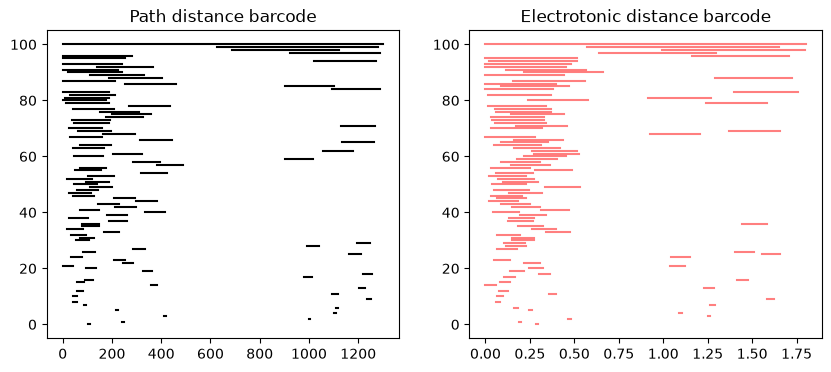

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for i, bar in enumerate(pb.bars):
    xs = [bar.birth, bar.death]
    ys = [i, i]
    axes[0].plot(xs, ys, color='black')
axes[0].set_title('Path distance barcode')

for i, bar in enumerate(eb.bars):
    xs = [bar.birth, bar.death]
    ys = [i, i]
    axes[1].plot(xs, ys, color='red', alpha=0.5)
axes[1].set_title('Electrotonic distance barcode')

Text(0.5, 1.0, 'Persistence diagram')

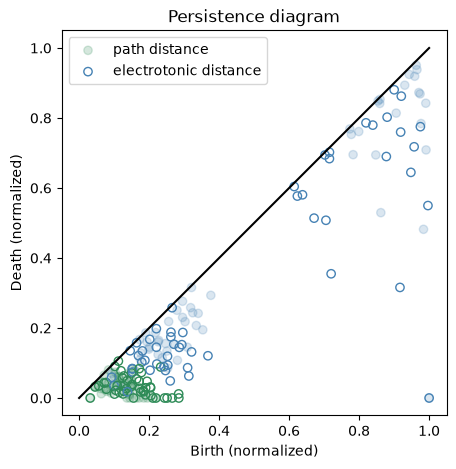

In [8]:
fig, ax = plt.subplots(figsize=(5, 5))

pb_norm = pb.normalized()
eb_norm = eb.normalized()

ax.scatter(
    [bar.birth for bar in pb_norm.bars],
    [bar.death for bar in pb_norm.bars],
    color=[bar.tip.domain_color for bar in pb_norm.bars],
    label='path distance',
    alpha=0.2,
)

ax.scatter(
    [bar.birth for bar in eb_norm.bars],
    [bar.death for bar in eb_norm.bars],
    color='none',
    label='electrotonic distance',
    edgecolors=[bar.tip.domain_color for bar in eb_norm.bars],
)

ax.plot([0, 1], [0, 1], color='black')
ax.set_xlabel('Birth (normalized)')
ax.set_ylabel('Death (normalized)')
ax.set_aspect('equal')
ax.legend()
ax.set_title('Persistence diagram')

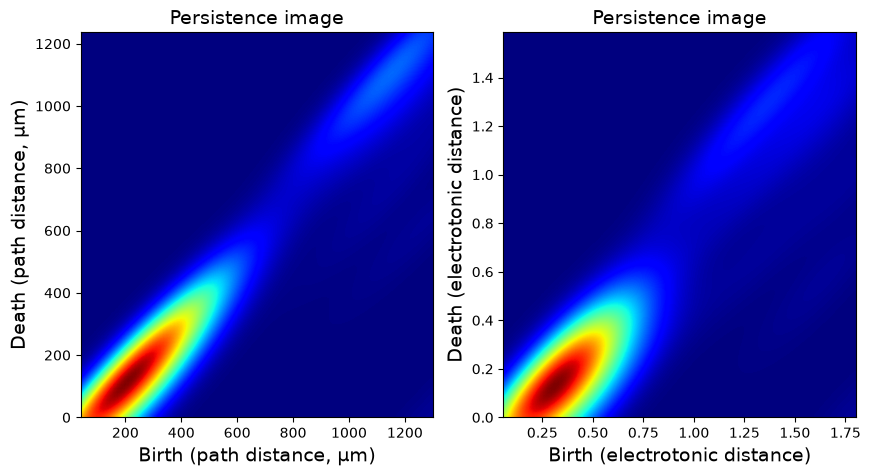

In [9]:
import tmd
from tmd.view import plot

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plt.sca(axes[0])
tmd.view.plot.persistence_image(pb.to_numpy(), new_fig=False,
    xlabel='Birth (path distance, µm)', ylabel='Death (path distance, µm)');

plt.sca(axes[1])
tmd.view.plot.persistence_image(eb.to_numpy(), new_fig=False,
    xlabel='Birth (electrotonic distance)', ylabel='Death (electrotonic distance)');

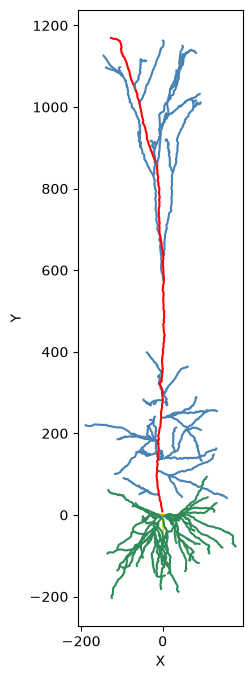

In [10]:
IDX = -1
sections_to_highlight = pb[IDX].path

fig, ax = plt.subplots(figsize=(8, 8))
model.sec_tree.plot(
    ax=ax, 
    show_domains=True,
    show_points=False,
    show_lines=True, 
    highlight_sections=sections_to_highlight # in red
)

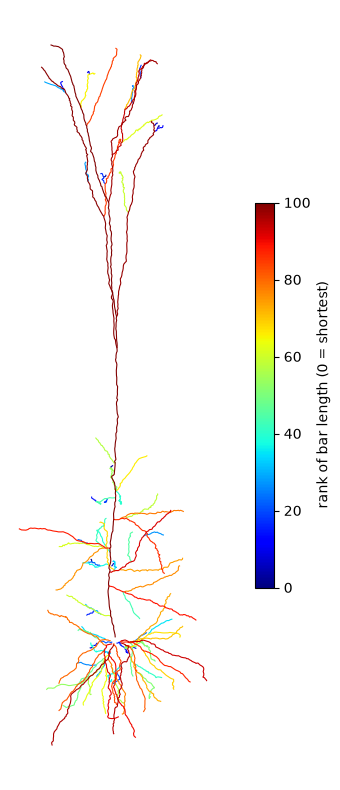

In [11]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

cmap = plt.get_cmap('jet')
n = len(pb)

fig, ax = plt.subplots(figsize=(10, 10))
for rank, bar in enumerate(pb): # shortest first, longest last
    color = cmap(rank / (n - 1))
    xs = [p.x for p in bar.points]
    ys = [p.y for p in bar.points]
    ax.plot(xs, ys, color=color, linewidth=0.8)

ax.set_aspect('equal')
ax.axis('off')
fig.colorbar(ScalarMappable(norm=Normalize(0, n - 1), cmap=cmap), ax=ax, shrink=0.5,
             label='rank of bar length (0 = shortest)')
